# Notebook 02: Data Cleaning and Preprocessing

## Section 1 — Load Data and Create a Working Copy

### Business Objective

Load the original ride-booking dataset and create a separate working copy for data cleaning.

### Why Is This Important?

The original dataset must remain unchanged so that we can compare the cleaned data with the source data and investigate any problems.

All cleaning operations will be performed on the working copy.

### Expected Outcome

* Load the original dataset successfully.
* Create a working DataFrame.
* Verify the number of rows and columns.
* Confirm that the source data remains unchanged.


In [1]:
import pandas as pd

# Load the original dataset
df_original = pd.read_excel("ncr_ride_bookings.xlsx")

# Create a working copy for cleaning
df_clean = df_original.copy()

# Check the original dataset
print("Original dataset shape:", df_original.shape)

# Check the working copy
print("Working dataset shape:", df_clean.shape)

# Verify that both DataFrames initially contain the same data
print(
    "Original and working copies are identical:",
    df_original.equals(df_clean)
)

# Display the first five rows
display(df_clean.head())

Original dataset shape: (150000, 22)
Working dataset shape: (150000, 22)
Original and working copies are identical: True


,Date,Month Name,Time,Booking ID,Booking Status,Customer ID,Vehicle Type,Pickup Location,Drop Location,Avg VTAT,...,Reason for cancelling by Customer,Cancelled Rides by Driver,Driver Cancellation Reason,Incomplete Rides,Incomplete Rides Reason,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Payment Method
0,2024-03-23,March,12:29:38,"""CNR5884300""",No Driver Found,"""CID1982111""",eBike,Palam Vihar,Jhilmil,0.0,...,NaN,0,NaN,0,NaN,0,0.00,0.0,0.0,NaN
1,2024-11-29,November,18:01:39,"""CNR1326809""",Incomplete,"""CID4604802""",Go Sedan,Shastri Nagar,Gurgaon Sector 56,4.9,...,NaN,0,NaN,1,Vehicle Breakdown,237,5.73,0.0,0.0,UPI
2,2024-08-23,August,08:56:10,"""CNR8494506""",Completed,"""CID9202816""",Auto,Khandsa,Malviya Nagar,13.4,...,NaN,0,NaN,0,NaN,627,13.58,4.9,4.9,Debit Card
3,2024-10-21,October,17:17:25,"""CNR8906825""",Completed,"""CID2610914""",Premier Sedan,Central Secretariat,Inderlok,13.1,...,NaN,0,NaN,0,NaN,416,34.02,4.6,5.0,UPI
4,2024-09-16,September,22:08:00,"""CNR1950162""",Completed,"""CID9933542""",Bike,Ghitorni Village,Khan Market,5.3,...,NaN,0,NaN,0,NaN,737,48.21,4.1,4.3,UPI


cleaning roadmap

In [ ]:
| Step | Task                                         | Decision                                             |
| ---- | -------------------------------------------- | ---------------------------------------------------- |
| 1    | Load data and create a working copy          | Start here                                           |
| 2    | Standardize column names and text formatting | Fix formatting inconsistencies                       |
| 3    | Convert and validate data types              | Ensure correct types                                 |
| 4    | Investigate repeated Booking IDs             | Determine whether they represent a source-data issue |
| 5    | Handle missing values                        | Use column-specific strategies                       |
| 6    | Validate categorical values                  | Check labels and categories                          |
| 7    | Investigate zero values and outliers         | Preserve valid business observations                 |
| 8    | Run final quality checks                     | Verify the cleaned data                              |
| 9    | Save the cleaned dataset                     | Prepare for business analysis                        |


#— Standardize Column Names and Text

## Business Objective

Standardize column names and text formatting to make the dataset easier to work with in Python, SQL, and machine-learning pipelines.

## Why Is This Important?

Column names containing spaces can make code harder to maintain. Inconsistent spaces in text values can also cause problems when grouping, filtering, and analyzing categories.

## Tasks

1. Convert column names to lowercase.
2. Replace spaces with underscores.
3. Remove unnecessary leading and trailing spaces from text values.
4. Preserve the original business meaning of every column.
5. Verify that the row and column counts have not changed.


In [3]:
# Display the current column names

print("Current column names:")

for column in df_clean.columns:
    print(column)

Current column names:
Date
Month Name
Time
Booking ID
Booking Status
Customer ID
Vehicle Type
Pickup Location
Drop Location
Avg VTAT
Avg CTAT
Cancelled Rides by Customer
Reason for cancelling by Customer
Cancelled Rides by Driver
Driver Cancellation Reason
Incomplete Rides
Incomplete Rides Reason
Booking Value
Ride Distance
Driver Ratings
Customer Rating
Payment Method


In [4]:
# Standardize column names

df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", "_", regex=True)
)

# Display standardized column names

print("Standardized column names:")

for column in df_clean.columns:
    print(column)

Standardized column names:
date
month_name
time
booking_id
booking_status
customer_id
vehicle_type
pickup_location
drop_location
avg_vtat
avg_ctat
cancelled_rides_by_customer
reason_for_cancelling_by_customer
cancelled_rides_by_driver
driver_cancellation_reason
incomplete_rides
incomplete_rides_reason
booking_value
ride_distance
driver_ratings
customer_rating
payment_method


In [7]:
# Verify the cleaned structure

print("Original dataset shape:", df_original.shape)
print("Working dataset shape:", df_clean.shape)

print("\nMissing values after formatting:")
print(df_clean.isnull().sum())

print("\nFirst five rows:")
display(df_clean.head())

Original dataset shape: (150000, 22)
Working dataset shape: (150000, 22)

Missing values after formatting:
date                                      0
month_name                                0
time                                      0
booking_id                                0
booking_status                            0
customer_id                               0
vehicle_type                              0
pickup_location                           0
drop_location                             0
avg_vtat                                  0
avg_ctat                                  0
cancelled_rides_by_customer               0
reason_for_cancelling_by_customer    139500
cancelled_rides_by_driver                 0
driver_cancellation_reason           123000
incomplete_rides                          0
incomplete_rides_reason              141000
booking_value                             0
ride_distance                             0
driver_ratings                            0
customer_rati

,date,month_name,time,booking_id,booking_status,customer_id,vehicle_type,pickup_location,drop_location,avg_vtat,...,reason_for_cancelling_by_customer,cancelled_rides_by_driver,driver_cancellation_reason,incomplete_rides,incomplete_rides_reason,booking_value,ride_distance,driver_ratings,customer_rating,payment_method
0,2024-03-23,March,12:29:38,"""CNR5884300""",No Driver Found,"""CID1982111""",eBike,Palam Vihar,Jhilmil,0.0,...,NaN,0,NaN,0,NaN,0,0.00,0.0,0.0,NaN
1,2024-11-29,November,18:01:39,"""CNR1326809""",Incomplete,"""CID4604802""",Go Sedan,Shastri Nagar,Gurgaon Sector 56,4.9,...,NaN,0,NaN,1,Vehicle Breakdown,237,5.73,0.0,0.0,UPI
2,2024-08-23,August,08:56:10,"""CNR8494506""",Completed,"""CID9202816""",Auto,Khandsa,Malviya Nagar,13.4,...,NaN,0,NaN,0,NaN,627,13.58,4.9,4.9,Debit Card
3,2024-10-21,October,17:17:25,"""CNR8906825""",Completed,"""CID2610914""",Premier Sedan,Central Secretariat,Inderlok,13.1,...,NaN,0,NaN,0,NaN,416,34.02,4.6,5.0,UPI
4,2024-09-16,September,22:08:00,"""CNR1950162""",Completed,"""CID9933542""",Bike,Ghitorni Village,Khan Market,5.3,...,NaN,0,NaN,0,NaN,737,48.21,4.1,4.3,UPI


In [8]:
# Check the current data type of every column

print("Current data types:")
print(df_clean.dtypes)

Current data types:
date                                 datetime64[us]
month_name                                      str
time                                         object
booking_id                                      str
booking_status                                  str
customer_id                                     str
vehicle_type                                    str
pickup_location                                 str
drop_location                                   str
avg_vtat                                    float64
avg_ctat                                    float64
cancelled_rides_by_customer                   int64
reason_for_cancelling_by_customer               str
cancelled_rides_by_driver                     int64
driver_cancellation_reason                      str
incomplete_rides                              int64
incomplete_rides_reason                         str
booking_value                                 int64
ride_distance                               

In [9]:
# Inspect date, time, and ID values

print("Date examples:")
print(df_clean["date"].head())

print("\nTime examples:")
print(df_clean["time"].head())

print("\nBooking ID examples:")
print(df_clean["booking_id"].head())

print("\nCustomer ID examples:")
print(df_clean["customer_id"].head())

Date examples:
0   2024-03-23
1   2024-11-29
2   2024-08-23
3   2024-10-21
4   2024-09-16
Name: date, dtype: datetime64[us]

Time examples:
0    12:29:38
1    18:01:39
2    08:56:10
3    17:17:25
4    22:08:00
Name: time, dtype: object

Booking ID examples:
0    "CNR5884300"
1    "CNR1326809"
2    "CNR8494506"
3    "CNR8906825"
4    "CNR1950162"
Name: booking_id, dtype: str

Customer ID examples:
0    "CID1982111"
1    "CID4604802"
2    "CID9202816"
3    "CID2610914"
4    "CID9933542"
Name: customer_id, dtype: str


In [10]:
# Remove surrounding quotation marks and whitespace from IDs

id_columns = ["booking_id", "customer_id"]

for column in id_columns:
    df_clean[column] = (
        df_clean[column]
        .str.strip()
        .str.strip('"')
    )

# Verify the cleaned IDs
print("Booking ID examples:")
print(df_clean["booking_id"].head())

print("\nCustomer ID examples:")
print(df_clean["customer_id"].head())

Booking ID examples:
0    CNR5884300
1    CNR1326809
2    CNR8494506
3    CNR8906825
4    CNR1950162
Name: booking_id, dtype: str

Customer ID examples:
0    CID1982111
1    CID4604802
2    CID9202816
3    CID2610914
4    CID9933542
Name: customer_id, dtype: str


In [11]:
# Check whether IDs still have surrounding quotation marks

print(
    "Booking IDs starting with a quote:",
    df_clean["booking_id"].str.startswith('"').sum()
)

print(
    "Customer IDs starting with a quote:",
    df_clean["customer_id"].str.startswith('"').sum()
)

print("\nDataset shape:", df_clean.shape)

Booking IDs starting with a quote: 0
Customer IDs starting with a quote: 0

Dataset shape: (150000, 22)


Convert the Date and Time Columns

In a ride-booking business, we want to answer questions such as:

Which day has the highest number of bookings?
Which month has the most cancellations?
During which hours do customers book the most rides?
Are cancellations more frequent during particular times?

In [12]:
# Validate the date column

df_clean["date"] = pd.to_datetime(
    df_clean["date"],
    errors="coerce"
)

print("Date data type:", df_clean["date"].dtype)
print("Missing dates:", df_clean["date"].isna().sum())
print("Earliest date:", df_clean["date"].min())
print("Latest date:", df_clean["date"].max())

Date data type: datetime64[us]
Missing dates: 0
Earliest date: 2024-01-01 00:00:00
Latest date: 2024-12-30 00:00:00


Validate the time column

In [13]:
# Validate time values without changing the original column

time_check = pd.to_datetime(
    df_clean["time"],
    format="%H:%M:%S",
    errors="coerce"
)

print("Total rows:", len(df_clean))
print("Invalid time values:", time_check.isna().sum())

print("\nSample validated times:")
print(time_check.head())

Total rows: 150000
Invalid time values: 0

Sample validated times:
0   1900-01-01 12:29:38
1   1900-01-01 18:01:39
2   1900-01-01 08:56:10
3   1900-01-01 17:17:25
4   1900-01-01 22:08:00
Name: time, dtype: datetime64[us]


Create a booking-hour column

In [14]:
# Extract the booking hour

df_clean["booking_hour"] = time_check.dt.hour

print("Booking hour examples:")
print(df_clean[["time", "booking_hour"]].head())

print("\nUnique booking hours:")
print(sorted(df_clean["booking_hour"].dropna().unique()))

Booking hour examples:
       time  booking_hour
0  12:29:38            12
1  18:01:39            18
2  08:56:10             8
3  17:17:25            17
4  22:08:00            22

Unique booking hours:
[np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12), np.int32(13), np.int32(14), np.int32(15), np.int32(16), np.int32(17), np.int32(18), np.int32(19), np.int32(20), np.int32(21), np.int32(22), np.int32(23)]


— Validate Numeric Columns

Now we need to confirm that the numeric columns contain valid values before conducting business analysis or machine learning.

Business purpose

A ride-booking company needs reliable financial, distance, timing, and rating data. For example:

Negative booking values could indicate invalid financial records.
Negative ride distances could indicate data errors.
Ratings outside the 0–5 range could be invalid.

We checked these rules during our initial data validation. Now let's verify them again in the cleaned dataset.

In [15]:
#  Validate numeric business columns

numeric_columns = [
    "avg_vtat",
    "avg_ctat",
    "booking_value",
    "ride_distance",
    "driver_ratings",
    "customer_rating"
]

print("Numeric column validation:\n")

for column in numeric_columns:
    print(f"--- {column} ---")
    print("Data type:", df_clean[column].dtype)
    print("Missing values:", df_clean[column].isna().sum())
    print("Minimum:", df_clean[column].min())
    print("Maximum:", df_clean[column].max())
    print()

Numeric column validation:

--- avg_vtat ---
Data type: float64
Missing values: 0
Minimum: 0.0
Maximum: 20.0

--- avg_ctat ---
Data type: float64
Missing values: 0
Minimum: 0.0
Maximum: 45.0

--- booking_value ---
Data type: int64
Missing values: 0
Minimum: 0
Maximum: 4277

--- ride_distance ---
Data type: float64
Missing values: 0
Minimum: 0.0
Maximum: 50.0

--- driver_ratings ---
Data type: float64
Missing values: 0
Minimum: 0.0
Maximum: 5.0

--- customer_rating ---
Data type: float64
Missing values: 0
Minimum: 0.0
Maximum: 5.0



In [16]:
# Check for invalid negative values

non_negative_columns = [
    "avg_vtat",
    "avg_ctat",
    "booking_value",
    "ride_distance"
]

for column in non_negative_columns:
    invalid_count = (df_clean[column] < 0).sum()
    print(f"{column}: {invalid_count} negative values")


# Check rating ranges: valid ratings should be between 0 and 5

rating_columns = [
    "driver_ratings",
    "customer_rating"
]

for column in rating_columns:
    invalid_count = (
        (df_clean[column] < 0) |
        (df_clean[column] > 5)
    ).sum()

    print(f"{column}: {invalid_count} ratings outside 0–5")

avg_vtat: 0 negative values
avg_ctat: 0 negative values
booking_value: 0 negative values
ride_distance: 0 negative values
driver_ratings: 0 ratings outside 0–5
customer_rating: 0 ratings outside 0–5


In [17]:
# Analyze zero values by booking status

zero_columns = [
    "avg_vtat",
    "avg_ctat",
    "booking_value",
    "ride_distance",
    "driver_ratings",
    "customer_rating"
]

for column in zero_columns:
    print(f"\n--- {column} ---")

    zero_counts = (
        df_clean[df_clean[column] == 0]
        .groupby("booking_status")
        .size()
    )

    print(zero_counts)


--- avg_vtat ---
booking_status
No Driver Found    10500
dtype: int64

--- avg_ctat ---
booking_status
Cancelled by Customer    10500
Cancelled by Driver      27000
No Driver Found          10500
dtype: int64

--- booking_value ---
booking_status
Cancelled by Customer    10500
Cancelled by Driver      27000
No Driver Found          10500
dtype: int64

--- ride_distance ---
booking_status
Cancelled by Customer    10500
Cancelled by Driver      27000
No Driver Found          10500
dtype: int64

--- driver_ratings ---
booking_status
Cancelled by Customer    10500
Cancelled by Driver      27000
Incomplete                9000
No Driver Found          10500
dtype: int64

--- customer_rating ---
booking_status
Cancelled by Customer    10500
Cancelled by Driver      27000
Incomplete                9000
No Driver Found          10500
dtype: int64


In [18]:
# Calculate zero percentages within each booking status

for column in zero_columns:
    print(f"\n--- {column} ---")

    zero_summary = (
        df_clean.assign(is_zero=df_clean[column] == 0)
        .groupby("booking_status")["is_zero"]
        .agg(["sum", "count", "mean"])
    )

    zero_summary["zero_percentage"] = (
        zero_summary["mean"] * 100
    ).round(2)

    print(zero_summary[["sum", "count", "zero_percentage"]])


--- avg_vtat ---
                         sum  count  zero_percentage
booking_status                                      
Cancelled by Customer      0  10500              0.0
Cancelled by Driver        0  27000              0.0
Completed                  0  93000              0.0
Incomplete                 0   9000              0.0
No Driver Found        10500  10500            100.0

--- avg_ctat ---
                         sum  count  zero_percentage
booking_status                                      
Cancelled by Customer  10500  10500            100.0
Cancelled by Driver    27000  27000            100.0
Completed                  0  93000              0.0
Incomplete                 0   9000              0.0
No Driver Found        10500  10500            100.0

--- booking_value ---
                         sum  count  zero_percentage
booking_status                                      
Cancelled by Customer  10500  10500            100.0
Cancelled by Driver    27000  27000     

### Zero-Value Handling Decisions

**Dataset:** Ride Booking Analytics
**Records:** 150,000

1. `booking_value`: Retain zero values because they occur in unsuccessful bookings and may represent no revenue.
2. `ride_distance`: Retain zero values because they occur in unsuccessful bookings and may represent trips that did not take place.
3. `avg_vtat`: Retain zero values for now. Investigate the meaning of zero for bookings with no driver found.
4. `avg_ctat`: Retain zero values for now because they are associated with unsuccessful bookings.
5. `driver_ratings`: Retain the original values. Investigate whether zero means unrated.
6. `customer_rating`: Retain the original values. Investigate whether zero means unrated.

**Decision:** No zero values will be replaced or deleted at this stage. Any changes will require confirmation of the business meaning.


In [19]:
# Final validation after numeric and zero-value checks

print("Dataset shape:", df_clean.shape)

print("\nMissing values in numeric columns:")
print(df_clean[numeric_columns].isna().sum())

print("\nBooking status counts:")
print(df_clean["booking_status"].value_counts())

print("\nNumber of duplicate rows:", df_clean.duplicated().sum())

Dataset shape: (150000, 23)

Missing values in numeric columns:
avg_vtat           0
avg_ctat           0
booking_value      0
ride_distance      0
driver_ratings     0
customer_rating    0
dtype: int64

Booking status counts:
booking_status
Completed                93000
Cancelled by Driver      27000
No Driver Found          10500
Cancelled by Customer    10500
Incomplete                9000
Name: count, dtype: int64

Number of duplicate rows: 0


Investigate Missing Values

In [20]:
# Step 4.1: Investigate missing values by booking status

columns_to_check = [
    "reason_for_cancelling_by_customer",
    "driver_cancellation_reason",
    "incomplete_rides_reason",
    "payment_method"
]

for column in columns_to_check:
    print(f"\n--- {column} ---")

    missing_summary = (
        df_clean.assign(is_missing=df_clean[column].isna())
        .groupby("booking_status")["is_missing"]
        .agg(["sum", "count", "mean"])
    )

    missing_summary["missing_percentage"] = (
        missing_summary["mean"] * 100
    ).round(2)

    print(
        missing_summary[
            ["sum", "count", "missing_percentage"]
        ]
    )


--- reason_for_cancelling_by_customer ---
                         sum  count  missing_percentage
booking_status                                         
Cancelled by Customer      0  10500                 0.0
Cancelled by Driver    27000  27000               100.0
Completed              93000  93000               100.0
Incomplete              9000   9000               100.0
No Driver Found        10500  10500               100.0

--- driver_cancellation_reason ---
                         sum  count  missing_percentage
booking_status                                         
Cancelled by Customer  10500  10500               100.0
Cancelled by Driver        0  27000                 0.0
Completed              93000  93000               100.0
Incomplete              9000   9000               100.0
No Driver Found        10500  10500               100.0

--- incomplete_rides_reason ---
                         sum  count  missing_percentage
booking_status                                  

In [21]:
# Step 4.3: Check missing values in relevant booking statuses

checks = {
    "reason_for_cancelling_by_customer": "Cancelled by Customer",
    "driver_cancellation_reason": "Cancelled by Driver",
    "incomplete_rides_reason": "Incomplete"
}

for column, status in checks.items():

    relevant_rows = df_clean[
        df_clean["booking_status"] == status
    ]

    missing_count = relevant_rows[column].isna().sum()

    print(f"\nColumn: {column}")
    print(f"Relevant status: {status}")
    print(f"Total relevant bookings: {len(relevant_rows)}")
    print(f"Missing reasons: {missing_count}")


Column: reason_for_cancelling_by_customer
Relevant status: Cancelled by Customer
Total relevant bookings: 10500
Missing reasons: 0

Column: driver_cancellation_reason
Relevant status: Cancelled by Driver
Total relevant bookings: 27000
Missing reasons: 0

Column: incomplete_rides_reason
Relevant status: Incomplete
Total relevant bookings: 9000
Missing reasons: 0


In [22]:
# Check payment methods for completed and incomplete rides

relevant_statuses = ["Completed", "Incomplete"]

payment_check = df_clean[
    df_clean["booking_status"].isin(relevant_statuses)
]

print("Completed and incomplete bookings:", len(payment_check))
print(
    "Missing payment methods:",
    payment_check["payment_method"].isna().sum()
)

Completed and incomplete bookings: 102000
Missing payment methods: 0


In [23]:
# Step 4.4: Inspect distinct categorical values

categorical_columns = [
    "booking_status",
    "vehicle_type",
    "reason_for_cancelling_by_customer",
    "driver_cancellation_reason",
    "incomplete_rides_reason",
    "payment_method"
]

for column in categorical_columns:
    print(f"\n{'=' * 60}")
    print(f"Column: {column}")
    print(f"Unique non-missing values: {df_clean[column].nunique()}")
    print("\nCategories:")

    print(
        sorted(
            df_clean[column].dropna().astype(str).unique()
        )
    )


Column: booking_status
Unique non-missing values: 5

Categories:
['Cancelled by Customer', 'Cancelled by Driver', 'Completed', 'Incomplete', 'No Driver Found']

Column: vehicle_type
Unique non-missing values: 7

Categories:
['Auto', 'Bike', 'Go Mini', 'Go Sedan', 'Premier Sedan', 'Uber XL', 'eBike']

Column: reason_for_cancelling_by_customer
Unique non-missing values: 5

Categories:
['AC is not working', 'Change of plans', 'Driver asked to cancel', 'Driver is not moving towards pickup location', 'Wrong Address']

Column: driver_cancellation_reason
Unique non-missing values: 4

Categories:
['Customer related issue', 'More than permitted people in there', 'Personal & Car related issues', 'The customer was coughing/sick']

Column: incomplete_rides_reason
Unique non-missing values: 3

Categories:
['Customer Demand', 'Other Issue', 'Vehicle Breakdown']

Column: payment_method
Unique non-missing values: 5

Categories:
['Cash', 'Credit Card', 'Debit Card', 'UPI', 'Uber Wallet']


In [24]:
# Check for leading or trailing spaces in categorical columns

categorical_columns = [
    "booking_status",
    "vehicle_type",
    "pickup_location",
    "drop_location",
    "reason_for_cancelling_by_customer",
    "driver_cancellation_reason",
    "incomplete_rides_reason",
    "payment_method"
]

for column in categorical_columns:
    non_missing = df_clean[column].dropna()

    extra_spaces = (
        non_missing != non_missing.str.strip()
    ).sum()

    print(f"{column}: {extra_spaces} values with extra spaces")

booking_status: 0 values with extra spaces
vehicle_type: 0 values with extra spaces
pickup_location: 0 values with extra spaces
drop_location: 0 values with extra spaces
reason_for_cancelling_by_customer: 0 values with extra spaces
driver_cancellation_reason: 0 values with extra spaces
incomplete_rides_reason: 0 values with extra spaces
payment_method: 0 values with extra spaces


In [25]:
# Check missing values and distinct categories

for column in categorical_columns:
    print(
        f"{column}: "
        f"{df_clean[column].nunique()} unique categories, "
        f"{df_clean[column].isna().sum()} missing values"
    )

booking_status: 5 unique categories, 0 missing values
vehicle_type: 7 unique categories, 0 missing values
pickup_location: 176 unique categories, 0 missing values
drop_location: 176 unique categories, 0 missing values
reason_for_cancelling_by_customer: 5 unique categories, 139500 missing values
driver_cancellation_reason: 4 unique categories, 123000 missing values
incomplete_rides_reason: 3 unique categories, 141000 missing values
payment_method: 5 unique categories, 48000 missing values


In [26]:
# Step 5.1: Validate booking and customer identifiers

print("Total records:", len(df_clean))

print("\nBooking ID validation:")
print("Unique booking IDs:", df_clean["booking_id"].nunique())
print("Missing booking IDs:", df_clean["booking_id"].isna().sum())
print(
    "Rows with repeated booking IDs:",
    df_clean["booking_id"].duplicated(keep=False).sum()
)

print("\nCustomer ID validation:")
print("Unique customer IDs:", df_clean["customer_id"].nunique())
print("Missing customer IDs:", df_clean["customer_id"].isna().sum())
print(
    "Rows with repeated customer IDs:",
    df_clean["customer_id"].duplicated(keep=False).sum()
)

Total records: 150000

Booking ID validation:
Unique booking IDs: 148767
Missing booking IDs: 0
Rows with repeated booking IDs: 2457

Customer ID validation:
Unique customer IDs: 148788
Missing customer IDs: 0
Rows with repeated customer IDs: 2418


In [27]:
# Find all records with repeated booking IDs

repeated_bookings = df_clean[
    df_clean["booking_id"].duplicated(keep=False)
].sort_values("booking_id")

print("Rows with repeated booking IDs:", len(repeated_bookings))

print("\nFirst 20 records:")
display(
    repeated_bookings[
        [
            "booking_id",
            "date",
            "time",
            "customer_id",
            "booking_status",
            "vehicle_type",
            "pickup_location",
            "drop_location",
            "booking_value",
            "ride_distance"
        ]
    ].head(20)
)

Rows with repeated booking IDs: 2457

First 20 records:


,booking_id,date,time,customer_id,booking_status,vehicle_type,pickup_location,drop_location,booking_value,ride_distance
9192,CNR1026036,2024-07-21,17:59:41,CID6974869,No Driver Found,Go Mini,Seelampur,Nehru Place,0,0.00
81334,CNR1026036,2024-10-15,18:17:23,CID6480133,Completed,Go Mini,Khandsa,Ashok Vihar,102,36.51
1353,CNR1029172,2024-01-19,17:00:57,CID2615731,Incomplete,Bike,Jhilmil,Narsinghpur,429,16.16
9587,CNR1029172,2024-12-17,19:19:02,CID6382731,Completed,Auto,Inderlok,Laxmi Nagar,332,36.38
82029,CNR1051228,2024-11-05,16:50:20,CID3177617,Completed,Auto,Dwarka Sector 21,Nehru Place,246,4.80
110412,CNR1051228,2024-01-31,08:42:04,CID5242056,Completed,Premier Sedan,Arjangarh,Yamuna Bank,930,13.06
87333,CNR1056023,2024-04-20,23:16:21,CID9367665,Completed,Premier Sedan,Badshahpur,Sultanpur,116,46.54
120008,CNR1056023,2024-07-07,17:18:49,CID4890470,Incomplete,Go Sedan,Meerut,Tilak Nagar,420,5.13
38548,CNR1058956,2024-10-15,13:33:55,CID1882606,Completed,Go Mini,Badshahpur,MG Road,194,24.65
71570,CNR1058956,2024-02-12,19:02:47,CID2451799,Cancelled by Customer,Premier Sedan,Patel Chowk,Kaushambi,0,0.00


In [28]:
# Count how frequently each booking ID appears

booking_id_counts = df_clean["booking_id"].value_counts()

print("Booking IDs appearing more than once:",
      (booking_id_counts > 1).sum())

print("\nFrequency of repeated booking IDs:")
print(booking_id_counts[booking_id_counts > 1].value_counts().sort_index())

Booking IDs appearing more than once: 1224

Frequency of repeated booking IDs:
count
2    1215
3       9
Name: count, dtype: int64


In [29]:
##Check whether repeated IDs have different customers

# Investigate how many customers share repeated booking IDs

repeated_ids = booking_id_counts[booking_id_counts > 1].index

repeated_booking_data = df_clean[
    df_clean["booking_id"].isin(repeated_ids)
]

customer_counts = (
    repeated_booking_data
    .groupby("booking_id")["customer_id"]
    .nunique()
)

print("Repeated IDs with multiple customer IDs:",
      (customer_counts > 1).sum())

print("Repeated IDs with only one customer ID:",
      (customer_counts == 1).sum())

Repeated IDs with multiple customer IDs: 1224
Repeated IDs with only one customer ID: 0


In [30]:
# Check date consistency for repeated booking IDs

date_counts = (
    repeated_booking_data
    .groupby("booking_id")["date"]
    .nunique()
)

print("Repeated IDs with multiple dates:",
      (date_counts > 1).sum())

print("Repeated IDs with only one date:",
      (date_counts == 1).sum())

Repeated IDs with multiple dates: 1219
Repeated IDs with only one date: 5


In [31]:
# Find booking IDs that repeat on the same date
same_date_ids = date_counts[date_counts == 1].index

# Display all records for these booking IDs
same_date_records = repeated_booking_data[
    repeated_booking_data["booking_id"].isin(same_date_ids)
].sort_values(["booking_id", "date"])

same_date_records[
    [
        "booking_id",
        "date",
        "customer_id",
        "booking_status",
        "vehicle_type",
        "pickup_location",
        "drop_location",
        "booking_value",
        "ride_distance"
    ]
]

,booking_id,date,customer_id,booking_status,vehicle_type,pickup_location,drop_location,booking_value,ride_distance
9080,CNR1401147,2024-01-06,CID6137990,Cancelled by Customer,eBike,Inderlok,Okhla,0,0.00
13018,CNR1401147,2024-01-06,CID8073095,Completed,Premier Sedan,Ramesh Nagar,Tilak Nagar,410,17.36
116184,CNR2735518,2024-09-09,CID7771380,Cancelled by Customer,Auto,Meerut,Green Park,0,0.00
136046,CNR2735518,2024-09-09,CID4162193,Completed,Premier Sedan,Noida Film City,Pataudi Chowk,259,7.06
96328,CNR3826271,2024-02-23,CID1946596,Completed,Auto,Patel Chowk,Delhi Gate,230,47.48
140988,CNR3826271,2024-02-23,CID9675113,Cancelled by Driver,Auto,Udyog Vihar,Jor Bagh,0,0.00
119334,CNR4767660,2024-07-11,CID6943921,Cancelled by Driver,Go Sedan,Paschim Vihar,RK Puram,0,0.00
147731,CNR4767660,2024-07-11,CID5913869,No Driver Found,Go Mini,Ramesh Nagar,Paharganj,0,0.00
71669,CNR5639336,2024-08-28,CID1977719,No Driver Found,Premier Sedan,Kashmere Gate ISBT,Malviya Nagar,0,0.00
89767,CNR5639336,2024-08-28,CID6022880,Completed,Auto,Rohini,Udyog Vihar,223,26.19


In [32]:
# Count bookings/records associated with each customer
customer_record_counts = df_clean["customer_id"].value_counts()

print("Total unique customers:", df_clean["customer_id"].nunique())

print(
    "Customers appearing more than once:",
    (customer_record_counts > 1).sum()
)

print("\nFrequency of customer records:")
print(
    customer_record_counts.value_counts()
    .sort_index()
    .head(10)
)

Total unique customers: 148788
Customers appearing more than once: 1206

Frequency of customer records:
count
1    147582
2      1200
3         6
Name: count, dtype: int64


In [33]:
# Find customers appearing more than once
repeated_customer_ids = customer_record_counts[
    customer_record_counts > 1
].index

# Extract all records for these customers
repeated_customer_data = df_clean[
    df_clean["customer_id"].isin(repeated_customer_ids)
].sort_values(["customer_id", "date"])

# Count distinct booking dates for each customer
customer_date_counts = (
    repeated_customer_data.groupby("customer_id")["date"].nunique()
)

print(
    "Customers with records on multiple dates:",
    (customer_date_counts > 1).sum()
)

print(
    "Customers with records on only one date:",
    (customer_date_counts == 1).sum()
)

Customers with records on multiple dates: 1201
Customers with records on only one date: 5


In [34]:
# Validate customer cancellation indicator
customer_cancel_check = (
    df_clean["cancelled_rides_by_customer"]
    == (df_clean["booking_status"] == "Cancelled by Customer").astype(int)
)

# Validate driver cancellation indicator
driver_cancel_check = (
    df_clean["cancelled_rides_by_driver"]
    == (df_clean["booking_status"] == "Cancelled by Driver").astype(int)
)

# Validate incomplete ride indicator
incomplete_check = (
    df_clean["incomplete_rides"]
    == (df_clean["booking_status"] == "Incomplete").astype(int)
)

print("Customer cancellation mismatches:", (~customer_cancel_check).sum())
print("Driver cancellation mismatches:", (~driver_cancel_check).sum())
print("Incomplete ride mismatches:", (~incomplete_check).sum())

Customer cancellation mismatches: 0
Driver cancellation mismatches: 0
Incomplete ride mismatches: 0


In [35]:
# Final dataset overview
print("FINAL DATASET SUMMARY")
print("-" * 40)

print("Total rows:", df_clean.shape[0])
print("Total columns:", df_clean.shape[1])
print("Unique booking IDs:", df_clean["booking_id"].nunique())
print("Unique customers:", df_clean["customer_id"].nunique())

print(
    "Exact duplicate rows:",
    df_clean.duplicated().sum()
)

print(
    "Total missing values:",
    df_clean.isna().sum().sum()
)

print("\nMissing values by column:")
print(
    df_clean.isna().sum()
    [df_clean.isna().sum() > 0]
    .sort_values(ascending=False)
)

print("\nBooking status distribution:")
print(
    df_clean["booking_status"]
    .value_counts()
)

FINAL DATASET SUMMARY
----------------------------------------
Total rows: 150000
Total columns: 23
Unique booking IDs: 148767
Unique customers: 148788
Exact duplicate rows: 0
Total missing values: 451500

Missing values by column:
incomplete_rides_reason              141000
reason_for_cancelling_by_customer    139500
driver_cancellation_reason           123000
payment_method                        48000
dtype: int64

Booking status distribution:
booking_status
Completed                93000
Cancelled by Driver      27000
No Driver Found          10500
Cancelled by Customer    10500
Incomplete                9000
Name: count, dtype: int64


In [36]:
# Count bookings by status
status_summary = (
    df_clean["booking_status"]
    .value_counts()
    .reset_index()
)

status_summary.columns = [
    "booking_status",
    "total_bookings"
]

# Calculate percentage of all bookings
status_summary["percentage"] = (
    status_summary["total_bookings"]
    / len(df_clean)
    * 100
).round(2)

# Display results
status_summary

,booking_status,total_bookings,percentage
0,Completed,93000,62.0
1,Cancelled by Driver,27000,18.0
2,No Driver Found,10500,7.0
3,Cancelled by Customer,10500,7.0
4,Incomplete,9000,6.0


In [38]:
status_summary.style.hide(axis="index")

booking_status,total_bookings,percentage
Completed,93000,62.000000
Cancelled by Driver,27000,18.000000
No Driver Found,10500,7.000000
Cancelled by Customer,10500,7.000000
Incomplete,9000,6.000000


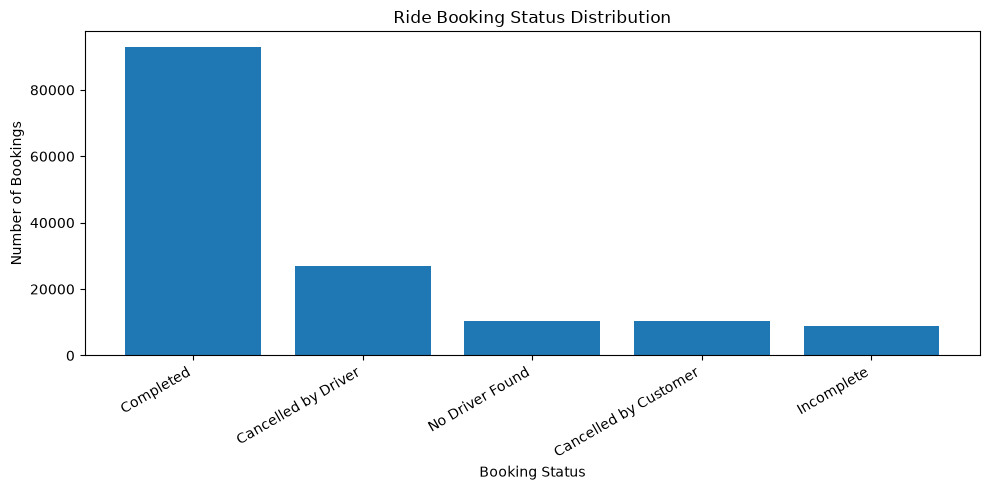

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    status_summary["booking_status"],
    status_summary["total_bookings"]
)

plt.title("Ride Booking Status Distribution")
plt.xlabel("Booking Status")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

In [40]:
# Filter bookings cancelled by customers
customer_cancelled = df_clean[
    df_clean["booking_status"] == "Cancelled by Customer"
]

# Count cancellation reasons
customer_cancel_reason_summary = (
    customer_cancelled["reason_for_cancelling_by_customer"]
    .value_counts()
    .reset_index()
)

customer_cancel_reason_summary.columns = [
    "cancellation_reason",
    "total_cancellations"
]

# Calculate percentage within customer-cancelled bookings
customer_cancel_reason_summary["percentage"] = (
    customer_cancel_reason_summary["total_cancellations"]
    / len(customer_cancelled)
    * 100
).round(2)

customer_cancel_reason_summary

,cancellation_reason,total_cancellations,percentage
0,Wrong Address,2362,22.50
1,Change of plans,2353,22.41
2,Driver is not moving towards pickup location,2335,22.24
3,Driver asked to cancel,2295,21.86
4,AC is not working,1155,11.00


In [41]:
# Save the cleaned dataset
df_clean.to_csv(
    "ride_booking_cleaned.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Cleaned dataset saved successfully!")
print("File name: ride_booking_cleaned.csv")
print("Dataset shape:", df_clean.shape)

Cleaned dataset saved successfully!
File name: ride_booking_cleaned.csv
Dataset shape: (150000, 23)


In [42]:
import os

file_name = "ride_booking_cleaned.csv"

print("File exists:", os.path.exists(file_name))

if os.path.exists(file_name):
    print("Full file path:", os.path.abspath(file_name))
    print("File size:", round(os.path.getsize(file_name) / (1024 * 1024), 2), "MB")

File exists: True
Full file path: C:\Users\SASWAT\ride_booking_cleaned.csv
File size: 20.83 MB
